# Лаба 3 — Классическое ML в NLP: векторизация, классификация, полнотекстовый поиск и LDA

Сквозной датасет — корпус гайдов [keqingmains.com](https://keqingmains.com) из лабы 1:
**очищенные тексты `../lab1/cleaned/*.txt`** (189 документов, класс `full`/`quick` —
префикс имени файла). Плейсхолдеры `[NUM]`/`[URL]` из конвейера очистки лабы 1 — часть
данных; при токенизации отбрасываются (скобки и цифры не проходят буквенный фильтр).

Целевая задача классификации — как в лабах 1–2: **full (развёрнутый гайд) vs quick
(компактный гайд)**, 68/121 документов — умеренный дисбаланс (36%/64%).

Шаги: **1** загрузка и стратифицированный сплит → **2** векторизация BoW / TF-IDF
(fit только на train) → **3** классификаторы Multinomial NB + Linear SVM с балансировкой →
**4** macro-метрики, confusion matrix, error analysis → **5** инвертированный индекс →
**6** поиск Okapi BM25 → **7** LDA + выбор K по когерентности c_v → **8** интерпретация тем.

## Шаг 0. 

In [1]:
import collections
import math
import os
import random
import re
import time
from functools import lru_cache

import matplotlib.pyplot as plt
import nltk

for pkg in ('stopwords', 'wordnet', 'omw-1.4'):
    try:
        nltk.data.find(f'corpora/{pkg}')
    except LookupError:
        nltk.download(pkg, quiet=True)

SEED = 42
CLEAN_DIR = os.path.join('..', 'lab1', 'cleaned')   # датасет: выгрузка лабы 1

print('NLTK-данные на месте. Зерно:', SEED)

NLTK-данные на месте. Зерно: 42


## Шаг 1. Загрузка корпуса и стратифицированный сплит 

Класс и персонаж — из имени файла `<type>-<slug>.txt`.

In [ ]:
def load_docs(clean_dir=CLEAN_DIR):
    out = []
    for name in sorted(os.listdir(clean_dir)):
        if not name.endswith('.txt'):
            continue
        dtype, slug = name[:-4].split('-', 1)
        if dtype not in ('full', 'quick'):
            continue
        with open(os.path.join(clean_dir, name), encoding='utf-8') as f:
            out.append({'file': name[:-4], 'type': dtype,
                        'character': slug, 'text': f.read()})
    return out


def stratified_split(items, test_size=0.2, seed=SEED):
    rng = random.Random(seed)
    train_i, test_i = [], []
    groups = collections.defaultdict(list)
    for i, d in enumerate(items):
        groups[d['type']].append(i)
    for idxs in groups.values():
        idxs = idxs[:]
        rng.shuffle(idxs)
        k = round(len(idxs) * (1 - test_size))
        train_i += idxs[:k]
        test_i += idxs[k:]
    return [items[i] for i in train_i], [items[i] for i in test_i]


def title(d):
    return f"{d['character'].replace('-', ' ').title()} ({d['type']})"


docs = load_docs()
train, test = stratified_split(docs)
tr = collections.Counter(d['type'] for d in train)
te = collections.Counter(d['type'] for d in test)
print(f'Корпус: {len(docs)} документов | {dict(collections.Counter(d["type"] for d in docs))}')
print(f'train: {len(train)} {dict(tr)} | test: {len(test)} {dict(te)}')
print(f'Доля full: train {tr["full"]/len(train):.1%} | test {te["full"]/len(test):.1%}'
      '  <- стратификация сохранила пропорцию')

Корпус: 189 документов | {'full': 68, 'quick': 121}
train: 151 {'full': 54, 'quick': 97} | test: 38 {'full': 14, 'quick': 24}
Доля full: train 35.8% | test 36.8%  <- стратификация сохранила пропорцию


### Общий препроцессинг: токенизация + лемматизация



In [ ]:
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

TOKEN_RE = re.compile(r'[a-z]{2,}')
STOP = set(stopwords.words('english')) | {'num', 'url'}   
_lemmatizer = WordNetLemmatizer()


@lru_cache(maxsize=None)
def lemma(word):
    return _lemmatizer.lemmatize(word)


def tokenize(text):
    """Нижний регистр -> буквенные токены >=2 симв. -> стоп-слова -> лемма WordNet"""
    return [lemma(w) for w in TOKEN_RE.findall(text.lower()) if w not in STOP]


t0 = time.time()
for d in docs:
    d['tokens'] = tokenize(d['text'])
print(f'Токенизация + лемматизация 189 документов: {time.time()-t0:.1f} с')

n_tok = sum(len(d['tokens']) for d in docs)
vocab_all = {t for d in docs for t in d['tokens']}
full_len = [len(d['tokens']) for d in docs if d['type'] == 'full']
quick_len = [len(d['tokens']) for d in docs if d['type'] == 'quick']
print(f'{n_tok:,} токенов, {len(vocab_all):,} уникальных лемм')
print(f'Средняя длина: full {sum(full_len)/len(full_len):,.0f} токенов | '
      f'quick {sum(quick_len)/len(quick_len):,.0f} токенов')

Токенизация + лемматизация 189 документов: 2.5 с
882,408 токенов, 11,509 уникальных лемм
Средняя длина: full 6,758 токенов | quick 3,495 токенов


## Шаг 2. Векторизация: Bag of Words и TF-IDF 


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

train_tokens = [d['tokens'] for d in train]
test_tokens = [d['tokens'] for d in test]
y_train = [d['type'] for d in train]
y_test = [d['type'] for d in test]

bow = CountVectorizer(analyzer=lambda d: d, min_df=2)
tfidf = TfidfVectorizer(analyzer=lambda d: d, min_df=2)

X_train_bow = bow.fit_transform(train_tokens)
X_test_bow = bow.transform(test_tokens)
X_train_tf = tfidf.fit_transform(train_tokens)
X_test_tf = tfidf.transform(test_tokens)

print(f'BoW    : train {X_train_bow.shape}  test {X_test_bow.shape}  '
      f'{X_train_bow.nnz:,} ненулевых в train')
print(f'TF-IDF : train {X_train_tf.shape}  test {X_test_tf.shape}  '
      f'{X_train_tf.nnz:,} ненулевых в train')

# сравнение размерностей словаря
V_raw = len(CountVectorizer(analyzer=lambda d: d).fit(train_tokens).vocabulary_)
V_all = len(CountVectorizer(analyzer=lambda d: d)
            .fit([d['tokens'] for d in docs]).vocabulary_)
train_types = {t for d in train for t in d['tokens']}
test_types = {t for d in test for t in d['tokens']}
oov = test_types - train_types
flat_test = [t for d in test for t in d['tokens']]
oov_tok = sum(t in oov for t in flat_test)
print(f'\nСловарь train без среза:  {V_raw:,} типов')
print(f'После min_df=2 (рабочий):  {X_train_tf.shape[1]:,} типов '
      f'(−{1 - X_train_tf.shape[1]/V_raw:.0%})')
print(f'Словарь по всему корпусу:  {V_all:,} типов — fit захватил бы test (утечка)')
print(f'OOV-типы test (нет в train): {len(oov):,} из {len(test_types):,} '
      f'({len(oov)/len(test_types):.1%}); это {oov_tok:,} токенов = '
      f'{oov_tok/len(flat_test):.2%} test-позиций')
print('\nПримеры OOV-типов test:', ', '.join(sorted(oov)[:12]))

BoW    : train (151, 6900)  test (38, 6900)  146,561 ненулевых в train
TF-IDF : train (151, 6900)  test (38, 6900)  146,561 ненулевых в train

Словарь train без среза:  10,801 типов
После min_df=2 (рабочий):  6,900 типов (−36%)
Словарь по всему корпусу:  11,509 типов — fit захватил бы test (утечка)
OOV-типы test (нет в train): 708 из 6,222 (11.4%); это 1,206 токенов = 0.67% test-позиций

Примеры OOV-типов test: aaaa, abnormally, aboard, abysmal, academy, accentuating, accessing, accomplishment, acupuncture, adagio, adhered, aedon


## Шаг 3. Классификаторы: Multinomial NB и Linear SVM (+ балансировка)



In [5]:
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.metrics import f1_score

rows = []
dummy = DummyClassifier(strategy='most_frequent').fit(X_train_tf, y_train)
pred_d = dummy.predict(X_test_tf)
rows.append(('Baseline most_frequent (всегда quick)',
             (pred_d == y_test).mean(), f1_score(y_test, pred_d, average='macro')))

configs = [
    ('NB | alpha=1.0 | априорные из train',
     MultinomialNB(alpha=1.0, fit_prior=True)),
    ('NB | alpha=1.0 | равные априорные (балансировка)',
     MultinomialNB(alpha=1.0, fit_prior=False)),
    ('NB | alpha=0.1 | априорные из train',
     MultinomialNB(alpha=0.1, fit_prior=True)),
    ('NB | alpha=0.1 | равные априорные (балансировка)',
     MultinomialNB(alpha=0.1, fit_prior=False)),
    ('Linear SVM | без весов классов',
     LinearSVC(random_state=SEED, dual='auto', max_iter=10000)),
    ('Linear SVM | class_weight=balanced (балансировка)',
     LinearSVC(class_weight='balanced', random_state=SEED, dual='auto', max_iter=10000)),
]
for name, model in configs:
    model.fit(X_train_tf, y_train)
    pred = model.predict(X_test_tf)
    rows.append((name, (pred == y_test).mean(), f1_score(y_test, pred, average='macro')))

print(f'{"конфигурация":55} {"accuracy":>9} {"macro-F1":>9}')
print('-' * 77)
for name, acc, mf1 in rows:
    print(f'{name:55} {acc:9.3f} {mf1:9.3f}')

конфигурация                                             accuracy  macro-F1
-----------------------------------------------------------------------------
Baseline most_frequent (всегда quick)                       0.632     0.387
NB | alpha=1.0 | априорные из train                         0.632     0.387
NB | alpha=1.0 | равные априорные (балансировка)            0.632     0.387
NB | alpha=0.1 | априорные из train                         0.816     0.770
NB | alpha=0.1 | равные априорные (балансировка)            0.684     0.649
Linear SVM | без весов классов                              0.737     0.717
Linear SVM | class_weight=balanced (балансировка)           0.737     0.725


In [6]:
nb_model = MultinomialNB(alpha=0.1, fit_prior=True)
svm_model = LinearSVC(class_weight='balanced', random_state=SEED,
                      dual='auto', max_iter=10000)
nb_model.fit(X_train_tf, y_train)
svm_model.fit(X_train_tf, y_train)
print('Оба классификатора обучены на TF-IDF (train):',
      f'NB {type(nb_model).__name__}, SVM {type(svm_model).__name__}')

Оба классификатора обучены на TF-IDF (train): NB MultinomialNB, SVM LinearSVC


## Шаг 4. Оценка качества: macro P/R/F1, Confusion Matrix, Error Analysis



In [7]:
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support)

LABELS = ['full', 'quick']


def evaluate(model, X, name):
    pred = model.predict(X)
    p, r, f1, _ = precision_recall_fscore_support(y_test, pred, average='macro')
    print(f'=== {name} ===')
    print(classification_report(y_test, pred, digits=3))
    print(f'Accuracy {accuracy_score(y_test, pred):.3f} | '
          f'Macro P {p:.3f} | Macro R {r:.3f} | Macro F1 {f1:.3f}\n')
    return pred


pred_nb = evaluate(nb_model, X_test_tf, 'Multinomial NB (alpha=0.1, априорные из train)')
pred_svm = evaluate(svm_model, X_test_tf, 'Linear SVM (class_weight=balanced)')

=== Multinomial NB (alpha=0.1, априорные из train) ===
              precision    recall  f1-score   support

        full      1.000     0.500     0.667        14
       quick      0.774     1.000     0.873        24

    accuracy                          0.816        38
   macro avg      0.887     0.750     0.770        38
weighted avg      0.857     0.816     0.797        38

Accuracy 0.816 | Macro P 0.887 | Macro R 0.750 | Macro F1 0.770

=== Linear SVM (class_weight=balanced) ===
              precision    recall  f1-score   support

        full      0.625     0.714     0.667        14
       quick      0.818     0.750     0.783        24

    accuracy                          0.737        38
   macro avg      0.722     0.732     0.725        38
weighted avg      0.747     0.737     0.740        38

Accuracy 0.737 | Macro P 0.722 | Macro R 0.732 | Macro F1 0.725



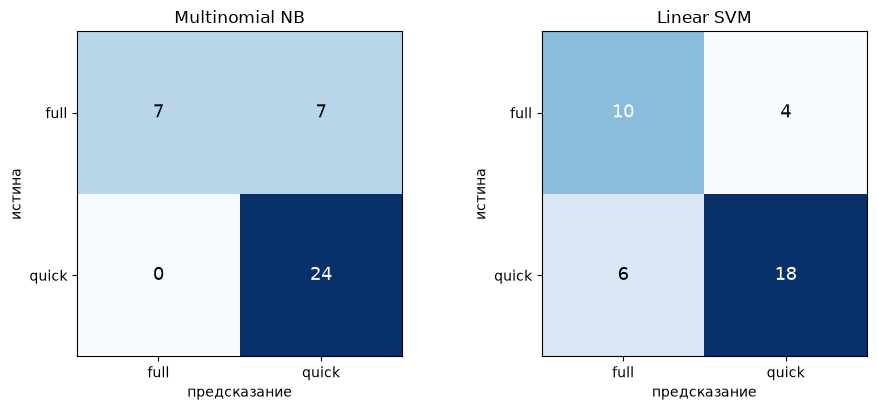

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4.2))
for ax, (name, pred) in zip(axes, [('Multinomial NB', pred_nb), ('Linear SVM', pred_svm)]):
    cm = confusion_matrix(y_test, pred, labels=LABELS)
    ax.imshow(cm, cmap='Blues')
    ax.set_xticks(range(2), LABELS)
    ax.set_yticks(range(2), LABELS)
    ax.set_xlabel('предсказание')
    ax.set_ylabel('истина')
    ax.set_title(name)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=13,
                    color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.tight_layout()
plt.savefig('confusion_matrix.png', bbox_inches='tight')
plt.show()

### Error Analysis: 5 ошибок Linear SVM

Для каждой ошибки — топ TF-IDF термы документа и «улики» SVM (термы с наибольшим
вкладом в `decision_function`: вклад = tf-idf × коэффициент; `->quick` тянет в quick,
`->full` — в full). Плюс длина документа: с лабы 1 известно, что full в среднем
в 2 раза длиннее — длина сильный, но не решающий прокси-признак.

In [9]:
mis = [i for i, (y, p) in enumerate(zip(y_test, pred_svm)) if y != p]
print(f'Ошибок Linear SVM на test: {len(mis)} из {len(y_test)}')
print('Полный список ошибок:', ', '.join(test[i]['file'] for i in mis))

feature_names = tfidf.get_feature_names_out()
coef = svm_model.coef_[0]                 # >0 -> класс quick, <0 -> класс full

for i in mis[:5]:
    d = test[i]
    vec = X_test_tf[i].toarray().ravel()
    tfidf_top = sorted(vec.nonzero()[0], key=lambda j: -vec[j])[:8]
    contrib = vec * coef
    evidence = sorted(contrib.nonzero()[0], key=lambda j: -abs(contrib[j]))[:8]
    print(f"\n--- {d['file']} | истина {y_test[i]} -> предсказано {pred_svm[i]} | "
          f"{len(d['tokens']):,} токенов")
    print('Топ TF-IDF термы :', ', '.join(feature_names[j] for j in tfidf_top))
    print('Улики SVM        :', ', '.join(
        f"{feature_names[j]}({'->quick' if contrib[j] > 0 else '->full'})"
        for j in evidence))
    print('Начало текста    :', ' '.join(d['tokens'][:40]), '...')

Ошибок Linear SVM на test: 10 из 38
Полный список ошибок: full-mika, full-ayato, full-baizhu, full-keqing, quick-yaoyao, quick-faruzan, quick-dendro-traveler, quick-wanderer, quick-kirara, quick-xiao

--- full-mika | истина full -> предсказано quick | 3,615 токенов
Топ TF-IDF термы : mika, spd, eula, attack, physical, team, buff, freminet
Улики SVM        : mika(->quick), attack(->quick), damage(->full), team(->quick), video(->full), dmg(->quick), burst(->full), constellation(->quick)
Начало текста    : mika guide written chasing haze art hope able provide useful intelligence help take weight shoulder display artwork table content introduction welcome traveler kqm guide mika chocobo surveyor knight favonius mika star cryo polearm user provides healing well physical dmg attack ...

--- full-ayato | истина full -> предсказано quick | 10,659 токенов
Топ TF-IDF термы : ayato, shunsuiken, team, rotation, skill, attack, burst, nilou
Улики SVM        : ayato(->quick), damage(->full), team(->q

### Разбор ошибок

Ошибок 10 из 38 (4 full→quick, 6 quick→full). Типовые причины видны на пяти примерах:

1. **`full-mika` (3615 токенов → quick)** — развёрнутый гайд, но по длине и лексике
   попадает в диапазон quick (медиана full ≈ 6.7 тыс. токенов). TF-IDF не видит длину
   напрямую (L2-нормировка), а улики распределились пополам: имя `mika(->quick)`
   (о Мике чаще пишут в quick-гайдах сокомандников), `attack/dmg(->quick)` против
   `damage/burst(->full)`. Классификатор «плавает» именно на таких пограничных длинах.
2. **`full-ayato` (10.7 тыс. токенов → quick)** — редкая ошибка для длинного документа:
   гайд насыщен разборами ротаций (`rotation`, `sample`), которые SVM связал с quick
   (в quick-гайдах краткие сэмплы ротаций — стандартный раздел), а счётчик `team` и
   имя персонажа тоже смотрят в quick.
3. **`full-baizhu` (5.9 тыс. → quick)** — «командный» гайд: Бай Чжу разбирается почти
   исключительно через команды с Nilou/Neuvillette (`team(->quick)`, `pc(->quick)`),
   мало собственных развернутых объяснений — стиль ближе к quick.
4. **`full-keqing` (13.6 тыс. → quick)** — показательная ошибка «отравленного»
   признака: `keqing(->quick)` — слово *keqing* встречается в 114 документах корпуса
   (сайт называется KeqingMains + кросс-упоминания в quick-гайдах), поэтому сам
   титульный термин гайда для SVM — улика в сторону quick. То же с `pc`
   (PC/mobile-разметка скриншотов).
5. **`quick-yaoyao` (2.3 тыс. → full)** — обратная ошибка: компактный quick-гайд
   написан развёрнуто, с объяснениями механик (`dendro(->full)`, `radish(->full)`,
   `yuegui(->full)` — термы «объяснительного» стиля), и короткая длина не спасает.

Общий вывод error analysis: классы full/quick различаются **стилем и плотностью**,
а не лексикой (вывод лаб 1–2 подтверждён) — модель ошибается на пограничных длинах
и на документах, чьи «фирменные» термы в корпусе встречаются чаще в другом классе.

## Шаг 5. Инвертированный индекс по всему корпусу

`term -> отсортированный список id документов` (постинги). Индекс строится по всем
189 документам (для поиска нет понятия train/test — ищем по всему корпусу). 

In [10]:
index = {}                                  # term -> [id документов] по возрастанию
doc_len = [len(d['tokens']) for d in docs]
doc_tf = [collections.Counter(d['tokens']) for d in docs]
avgdl = sum(doc_len) / len(doc_len)

for i in range(len(docs)):
    for term in doc_tf[i]:                 # уникальные термы документа
        index.setdefault(term, []).append(i)   # i растут -> постинги уже отсортированы

n_postings = sum(len(p) for p in index.values())
df1 = sum(1 for p in index.values() if len(p) == 1)
print(f'Терминов в индексе: {len(index):,} | всего постингов: {n_postings:,} | '
      f'термов ровно в 1 документе: {df1:,}')
print(f'Средняя длина документа: {avgdl:,.0f} токенов')
print()
for term in ('burst', 'vape', 'albedo', 'cooldown'):
    p = index[term]
    print(f'{term!r:12} df={len(p):3}  первые документы: '
          f"{', '.join(title(docs[i]) for i in p[:3])}")
top_df = sorted(index, key=lambda t: -len(index[t]))[:5]
print('\nТоп-5 термов по df:', ', '.join(f'{t} ({len(index[t])})' for t in top_df))

Терминов в индексе: 11,509 | всего постингов: 188,443 | термов ровно в 1 документе: 3,831


Средняя длина документа: 4,669 токенов

'burst'      df=189  первые документы: Albedo (full), Aloy (full), Amber (full)
'vape'       df= 65  первые документы: Ayato (full), Baizhu (full), Barbara (full)
'albedo'     df=114  первые документы: Albedo (full), Aloy (full), Amber (full)
'cooldown'   df=177  первые документы: Albedo (full), Aloy (full), Amber (full)

Топ-5 термов по df: table (189), content (189), effect (189), character (189), energy (189)


## Шаг 6. Полнотекстовый поиск Okapi BM25

Запрос прогоняется через тот же конвейер токенизации → леммы, которые есть в индексе,
→ кандидаты = объединение постингов → скоринг по Okapi BM25:

$$\text{score}(q,D)=\sum_{t \in q} \text{idf}(t)\cdot
\frac{\text{tf}(t,D)\,(k_1+1)}{\text{tf}(t,D)+k_1\left(1-b+b\frac{|D|}{\text{avgdl}}\right)},
\qquad \text{idf}(t)=\ln\frac{N-\text{df}(t)+0.5}{\text{df}(t)+0.5}+1$$

$k_1=1.5$, $b=0.75$ (каноничные значения Okapi): $k_1$ насыщает частоту терма,
$b$ нормирует на длину документа — критично для корпуса, где full-гайд длиннее
quick-гайда в разы.

In [11]:
K1, B = 1.5, 0.75
N = len(docs)


def bm25_idf(term):
    df_t = len(index.get(term, ()))
    return math.log((N - df_t + 0.5) / (df_t + 0.5) + 1)   # сглаженный Okapi IDF


def bm25_search(query, top=5):
    """Запрос -> леммы -> кандидаты из инвертированного индекса -> ранжирование BM25"""
    terms = [t for t in tokenize(query) if t in index]
    scores = collections.defaultdict(float)
    for t in terms:
        w = bm25_idf(t)
        for i in index[t]:
            tf = doc_tf[i][t]
            scores[i] += w * tf * (K1 + 1) / (tf + K1 * (1 - B + B * doc_len[i] / avgdl))
    ranked = sorted(scores.items(), key=lambda kv: -kv[1])[:top]
    return terms, ranked


QUERIES = [
    'Bennett ATK buff and healing',
    'Dendro cores and Bloom teams with Hydro',
    'Best weapons for Hu Tao vaporize',
]

for query in QUERIES:
    terms, ranked = bm25_search(query)
    print(f'\nЗапрос: {query!r}')
    print(f'Леммы запроса в индексе: {", ".join(terms)}')
    for rank, (i, s) in enumerate(ranked, 1):
        print(f'  {rank}. {s:9.3f}  {title(docs[i])}')


Запрос: 'Bennett ATK buff and healing'
Леммы запроса в индексе: bennett, atk, buff, healing
  1.     0.513  Bennett (quick)
  2.     0.513  Bennett (full)
  3.     0.507  Furina (full)
  4.     0.505  Xianyun (quick)
  5.     0.504  Gaming (quick)

Запрос: 'Dendro cores and Bloom teams with Hydro'
Леммы запроса в индексе: dendro, core, bloom, team, hydro
  1.     4.002  Nilou (full)
  2.     3.994  Kaveh (quick)
  3.     3.992  Kaveh (full)
  4.     3.986  Nilou (quick)
  5.     3.965  Lauma (quick)

Запрос: 'Best weapons for Hu Tao vaporize'
Леммы запроса в индексе: best, weapon, hu, tao, vaporize
  1.     5.587  Yelan (full)
  2.     5.555  Furina (full)
  3.     5.529  Hu Tao (quick)
  4.     5.474  Xingqiu (full)
  5.     5.469  Hu Tao (full)


Что видно на трёх запросах:

1. **Bennett ATK buff and healing** — собственные гайды Беннетта наверху, но отрыв
   от Furina/Xianyun/Gaming микроскопический (0.51 против 0.50): `bennett`
   встречается в 166 из 189 документов (его тащат почти в каждую команду), поэтому
   IDF терма низкий и запрос слабо дискриминирует. Наглядная роль IDF в BM25.
2. **Dendro cores and Bloom teams with Hydro** — семантическое попадание без единого
   имени в запросе: топ — Nilou и Kaveh (центральные персонажи Bloom-архетипа) и
   Lauma. Ранжирование нашло «о чём» документы, опираясь на механики
   `dendro/core/bloom/hydro`.
3. **Best weapons for Hu Tao vaporize** — поучительный сбой ожиданий: топ-2 — гайды
   Yelan и Furina, а гайды самой Ху Тао только 3-й и 5-й. Соконтекст `hu tao +
   weapon + vaporize` плотнее всего встречается в гайдах её сокомандников по vape-тим
   (double hydro с Yelan/Xingqiu), плюс нормировка длины (b=0.75) понижает длинные
   full-гайды Ху Тао, где термы размазаны. BM25 ранжирует по встречаемости термов
   запроса, а не по «титульности» документа.

## Шаг 7. Тематическое моделирование LDA + выбор K по когерентности c_v

Словарь дополнительно прореживается `filter_extremes(no_below=3, no_above=0.35)`:
термы меньше 3 документов — шум, термы больше 35% корпуса общие и потому
бесполезные для разделения тем. 

Словарь LDA после filter_extremes: 4,981 типов


K= 3  c_v=0.3648


K= 4  c_v=0.3573


K= 5  c_v=0.3913


K= 6  c_v=0.4002


K= 7  c_v=0.3821


... (4 outputs left out)

K=12  c_v=0.3850


K=13  c_v=0.3830


K=14  c_v=0.3788


K=15  c_v=0.3878

Сетка 13 моделей: 209 с


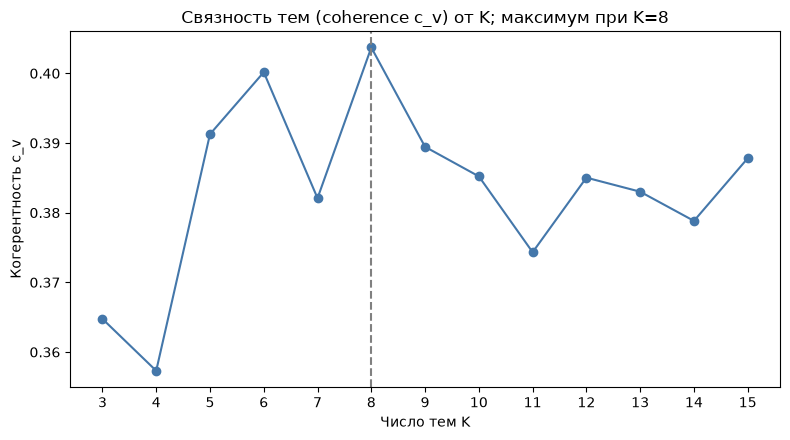

Оптимальное K по c_v: 8


In [12]:
from gensim.corpora import Dictionary
from gensim.models import CoherenceModel, LdaModel

texts = [d['tokens'] for d in docs]
dct = Dictionary(texts)
dct.filter_extremes(no_below=3, no_above=0.35)
lda_corpus = [dct.doc2bow(t) for t in texts]
print(f'Словарь LDA после filter_extremes: {len(dct):,} типов')

K_GRID = list(range(3, 16))
cv_scores = {}
t0 = time.time()
for k in K_GRID:
    lda = LdaModel(corpus=lda_corpus, id2word=dct, num_topics=k,
                   random_state=SEED, passes=20, iterations=200,
                   alpha='auto', minimum_probability=0.0)
    cv_scores[k] = CoherenceModel(model=lda, texts=texts, dictionary=dct,
                                  coherence='c_v', processes=1).get_coherence()
    print(f'K={k:2d}  c_v={cv_scores[k]:.4f}')
print(f'\nСетка {len(K_GRID)} моделей: {time.time()-t0:.0f} с')

best_k = max(cv_scores, key=cv_scores.get)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(list(cv_scores), list(cv_scores.values()), marker='o', color='#4477aa')
ax.axvline(best_k, ls='--', c='gray')
ax.set_xticks(K_GRID)
ax.set_xlabel('Число тем K')
ax.set_ylabel('Когерентность c_v')
ax.set_title(f'Связность тем (coherence c_v) от K; максимум при K={best_k}')
plt.tight_layout()
plt.savefig('lda_coherence.png', bbox_inches='tight')
plt.show()
print('Оптимальное K по c_v:', best_k)

## Шаг 8. Интерпретация тем: топ-10 слов и названия

Финальная модель на оптимальном K (побольше проходов для устойчивости), топ-10 слов
каждой темы по весам φ(w|t).

In [ ]:
lda_final = LdaModel(corpus=lda_corpus, id2word=dct, num_topics=best_k,
                     random_state=SEED, passes=40, iterations=400,
                     alpha='auto', minimum_probability=0.0)

topics = lda_final.show_topics(num_topics=best_k, num_words=10, formatted=False)
for tid, words in topics:
    print(f'Тема {tid}: ' + ', '.join(w for w, _ in words))

doc_topics = [max(lda_final.get_document_topics(b), key=lambda x: x[1])[0]
              for b in lda_corpus]
print('\nДокументов с доминирующей темой:',
      dict(sorted(collections.Counter(doc_topics).items())))

Тема 0: nilou, razor, kaveh, alhaitham, skirk, quicken, aggravate, bountiful, barbara, dori
Тема 1: lunar, navia, columbina, xiao, ineffa, noelle, faruzan, lauma, aino, flins
Тема 2: yoimiya, mavuika, nightsoul, chevreuse, candace, iansan, clorinde, citlali, ororon, overloaded
Тема 3: itto, yanfei, gorou, ningguang, gaming, freminet, diluc, chiori, xianyun, na
Тема 4: neuvillette, mika, arlecchino, faruzan, yan, lan, ca, aggravate, alhaitham, hypercarry
Тема 5: klee, durin, dehya, hexerei, escoffier, nicole, varka, sigewinne, yun, jin
Тема 6: keqing, stellar, conduct, qiqi, odette, wriothesley, sandrone, tighnari, alyosha, ineffa
Тема 7: ayaka, eula, chongyun, xinyan, barbara, ca, aloy, icy, comp, quill

Документов с доминирующей темой: {0: 25, 1: 21, 2: 21, 3: 15, 4: 20, 5: 21, 6: 16, 7: 50}


### Названия и интерпретация тем (K = 8)

Корпус устроен «один документ — один персонаж», поэтому LDA-темы — это прежде всего
**кластеры персонажей по элементу/архетипу/свежести**, скреплённые словами механик:

| Тема | Топ-слова (фрагмент) | Название |
|---|---|---|
| 0 | nilou, kaveh, quicken, aggravate, bountiful, barbara, dori | **«Дендро-реакции: Bloom (Nilou) и Quicken/Aggravate»** — дендро-архетипы: bloom-команды Nilou и электро-дендро Aggravate |
| 1 | lunar, navia, columbina, ineffa, lauma, aino, flins | **«Новые персонажи Nod-Krai / Lunar-хроники»** — временной кластер самых свежих гайдов (Lunar, Ineffa, Lauma, Aino, Flins) |
| 2 | yoimiya, mavuika, nightsoul, chevreuse, iansan, citlali, overloaded | **«Пиро и Natlan: Nightsoul, Overload»** — пиро-дамагеры и механика Natlan (nightsoul, overload-тимы Chevreuse) |
| 3 | itto, gorou, ningguang, chiori, xianyun, na | **«Гео-команды и Normal Attack-дамагеры»** — гео-ядро (Itto+Gorou) и персонажи, играющие от нормалок (`na`) |
| 4 | neuvillette, arlecchino, ca, hypercarry, aggravate, lan | **«Charged Attack и hypercarry»** — `ca` (charged attack) — фирменный стиль Neuvillette; гипер-керри-компоновки |
| 5 | klee, durin, hexerei, escoffier, sigewinne, varka | **«Hexerei и редкие персонажи»** — второй кластер новинок + Nod-Krai-механика Hexerei; Klee и Durin связаны лором |
| 6 | keqing, stellar, conduct, qiqi, wriothesley, ineffa | **«Электро и механика Stellar Conduct»** — электро-персонажи + новая электро-механика Nod-Krai (`stellar conduct`) |
| 7 | ayaka, eula, chongyun, aloy, icy, comp, quill | **«Крио-дамагеры + командный catch-all»** — крио-ядро (Ayaka/Eula freeze-melt), но примесь общих слов `comp`/`ca` делает тему «магнитом»: она доминирует в 50 документах из 189 |

Наблюдения: (1) связующие слова тем — не стоп-слова, а **игровые механики**
(quicken, nightsoul, stellar conduct, charged attack) — LDA действительно нашла
семантику, а не частотный шум; (2) две темы (1 и 5) — «свежесть» контента, а не
геймплей: новые гайды обсуждают новых персонажей и их же механики, и LDA
группирует их вместе; (3) признаки деградации — тема 7 с общими словами
`comp`/`ca`/`quill`, стягивающая половину корпуса, намёк, что K=8 на пределе
разрешения этого корпуса (по графику c_v K=6 почти неотличим: 0.400 против 0.404).